# Agent的基本使用

## 1、Agent中模型的传入方式

### 1.1 直接传入字符串

In [1]:
from dotenv import load_dotenv
from langchain.agents import create_agent

load_dotenv(override=True)

agent = create_agent(
    model= "deepseek:deepseek-v4-flash"   # 调用的是 ChatDeepSeek()，其实会自动从配置文件种读取api_key 和 base_url
)

print(type(agent))

<class 'langgraph.graph.state.CompiledStateGraph'>


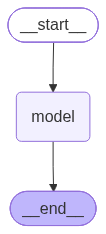

In [2]:
from IPython.display import Image, display
display(Image(agent.get_graph().draw_mermaid_png()))

### 1.2 传入模型实例

<class 'langgraph.graph.state.CompiledStateGraph'>


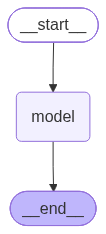

In [3]:
import os
from langchain.chat_models import init_chat_model
from dotenv import load_dotenv
from langchain.agents import create_agent

load_dotenv(override=True)

model = init_chat_model(
    model="deepseek:deepseek-v4-flash",  # 调用的是ChatDeepSeek()
)

# model = init_chat_model(
#     model="deepseek-v4-flash",
#     model_provider="deepseek",
#     api_key=os.getenv("DEEPSEEK_API_KEY"),
#     base_url=os.getenv("DEEPSEEK_BASE_URL")
# )

agent = create_agent(
    model=model
)

print(type(agent))

from IPython.display import Image, display
display(Image(agent.get_graph().draw_mermaid_png()))

## 2、如何调用Agent

举例1：

In [4]:
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
from dotenv import load_dotenv
import os
load_dotenv(override=True)
from rich import print as rprint

# 以init_chat_model为例
# model = init_chat_model(
#     model="gpt-5.4-mini",
#     model_provider="openai",
#     api_key=os.getenv("CLOSEAI_API_KEY"),
#     base_url=os.getenv("CLOSEAI_BASE_URL")
# )

model = init_chat_model(
    model="deepseek-v4-flash",
    model_provider="deepseek",
    api_key=os.getenv("DEEPSEEK_API_KEY"),
    base_url=os.getenv("DEEPSEEK_BASE_URL")
)

agent = create_agent(
    model=model
)

# 调用
# response= agent.invoke({
#     "messages":[
#         {"role":"user","content":"你好"}
#     ]
# })

# 简化：默认是HumanMessage
response= agent.invoke({
    "messages":[
        "你好"
    ]
})

rprint(response)
# 获取最终回答
final_answer = response['messages'][-1].content
print(final_answer)

{
    'messages': [
        HumanMessage(
            content='你好',
            additional_kwargs={},
            response_metadata={},
            id='12ac2124-269d-4794-a923-b4c18bf81a42'
        ),
        AIMessage(
            content='你好！很高兴见到你 😊\n\n有什么我可以帮你的吗？无论是问题、学习、写作还是随便聊聊，都可以。',
            additional_kwargs={
                'refusal': None,
                'reasoning_content': 'The user just said "你好" (hello) in Chinese. I should respond warmly and 
briefly, in Chinese, and offer to help. No need for lengthy response. Maybe ask what they need help with. Keep it 
natural and friendly.'
            },
            response_metadata={
                'token_usage': {
                    'completion_tokens': 75,
                    'prompt_tokens': 31,
                    'total_tokens': 106,
                    'completion_tokens_details': {
                        'accepted_prediction_tokens': None,
                        'audio_tokens': None,
                        'reasoning_tokens': 48,
                        'rejected_prediction_tokens': None
                    },
                    'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0},
                    'prompt_cache_hit_tokens': 0,
                    'prompt_cache_miss_tokens': 31
                },
                'model_provider': 'deepseek',
                'model_name': 'deepseek-flash',
                'system_fingerprint': 'aeb56401ca74e127821c4f9126dcb669',
                'id': 'd789986c-6347-41da-95a1-e4cdfaea28d3',
                'finish_reason': 'stop',
                'logprobs': None
            },
            id='lc_run--01a129aa-a015-7073-9619-66fb7c4fc10d-0',
            tool_calls=[],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 31,
                'output_tokens': 75,
                'total_tokens': 106,
                'input_token_details': {'cache_read': 0},
                'output_token_details': {'reasoning': 48}
            }
        )
    ]
}

你好！很高兴见到你 😊

有什么我可以帮你的吗？无论是问题、学习、写作还是随便聊聊，都可以。


举例2：

In [5]:
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
from dotenv import load_dotenv
import os
load_dotenv(override=True)
from rich import print as rprint

# 以init_chat_model为例
# model = init_chat_model(
#     model="gpt-5.4-mini",
#     model_provider="openai",
#     api_key=os.getenv("CLOSEAI_API_KEY"),
#     base_url=os.getenv("CLOSEAI_BASE_URL")
# )

model = init_chat_model(
    model="deepseek-v4-flash",
    model_provider="deepseek",
    api_key=os.getenv("DEEPSEEK_API_KEY"),
    base_url=os.getenv("DEEPSEEK_BASE_URL")
)

agent = create_agent(
    model=model
)

# 调用
response= agent.invoke({
    "messages":[
        {"role":"system","content":"你是一个精通数学的老师，擅长以通俗易懂的方式讲解数学问题"},
        {"role":"user","content":"100 + 20 * 3 = ？"}
    ]
})


rprint(response)

{
    'messages': [
        SystemMessage(
            content='你是一个精通数学的老师，擅长以通俗易懂的方式讲解数学问题',
            additional_kwargs={},
            response_metadata={},
            id='b795e7cf-8ae9-4e26-9262-b5b4294280cc'
        ),
        HumanMessage(
            content='100 + 20 * 3 = ？',
            additional_kwargs={},
            response_metadata={},
            id='cc3797af-89f2-4a58-9ec8-d36377577f89'
        ),
        AIMessage(
            content='160\n\n因为先算乘法：20 × 3 = 60，再算加法：100 + 60 = 160。',
            additional_kwargs={
                'refusal': None,
                'reasoning_content': 'We need answer Chinese. Need compute according order operations 
multiplication first 20*3=60 +100=160. Need perhaps mention not 360. User asks 100 + 20 * 3 = ? We should answer 
concise. In Chinese. Ensure no issue.'
            },
            response_metadata={
                'token_usage': {
                    'completion_tokens': 82,
                    'prompt_tokens': 54,
                    'total_tokens': 136,
                    'completion_tokens_details': {
                        'accepted_prediction_tokens': None,
                        'audio_tokens': None,
                        'reasoning_tokens': 54,
                        'rejected_prediction_tokens': None
                    },
                    'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0},
                    'prompt_cache_hit_tokens': 0,
                    'prompt_cache_miss_tokens': 54
                },
                'model_provider': 'deepseek',
                'model_name': 'deepseek-flash',
                'system_fingerprint': 'aeb56401ca74e127821c4f9126dcb669',
                'id': '7efdff5a-d5d6-474b-8e48-95becd0f91bd',
                'finish_reason': 'stop',
                'logprobs': None
            },
            id='lc_run--01a129aa-a4f1-7f43-bd91-7d942392065e-0',
            tool_calls=[],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 54,
                'output_tokens': 82,
                'total_tokens': 136,
                'input_token_details': {'cache_read': 0},
                'output_token_details': {'reasoning': 54}
            }
        )
    ]
}

## 3、如何绑定工具，并调用工具

### 举例1：绑定一个自定义的工具

In [6]:
from langchain_core.tools import tool
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
from dotenv import load_dotenv
import os
load_dotenv(override=True)
from rich import print as rprint

# 以init_chat_model为例
# model = init_chat_model(
#     model="gpt-5.4-mini",
#     model_provider="openai",
#     api_key=os.getenv("CLOSEAI_API_KEY"),
#     base_url=os.getenv("CLOSEAI_BASE_URL")
# )

model = init_chat_model(
    model="deepseek-v4-flash",
    model_provider="deepseek",
    api_key=os.getenv("DEEPSEEK_API_KEY"),
    base_url=os.getenv("DEEPSEEK_BASE_URL")
)


# 定义一个工具
@tool(parse_docstring=True)
def get_weather(city : str):
    """
    查询天气的工具

    Args:
        city : 具体的城市
    """
    return f"{city}天气晴朗，温度是15℃"


agent = create_agent(
    model = model,
    tools = [get_weather]
)


response = agent.invoke({
    "messages": [
        {"role":"system","content":"你是一个查询天气的助手，根据用户的提问查询天气。如果问题跟天气无关，你可以说：我不清楚这个问题的答案"},
        {"role":"user","content":"北京的天气如何？"}
    ]
})

rprint(response)

{
    'messages': [
        SystemMessage(
            content='你是一个查询天气的助手，根据用户的提问查询天气。如果问题跟天气无关，你可以说：我不清楚这个问题
的答案',
            additional_kwargs={},
            response_metadata={},
            id='702f99ee-9170-4ba8-87ce-83f6c2dbc3c4'
        ),
        HumanMessage(
            content='北京的天气如何？',
            additional_kwargs={},
            response_metadata={},
            id='0e20d074-abfb-41ff-9a78-bf3fb1437837'
        ),
        AIMessage(
            content='',
            additional_kwargs={
                'refusal': None,
                'reasoning_content': "The user asks about Beijing's weather. I should call the get_weather tool."
            },
            response_metadata={
                'token_usage': {
                    'completion_tokens': 56,
                    'prompt_tokens': 325,
                    'total_tokens': 381,
                    'completion_tokens_details': {
                        'accepted_prediction_tokens': None,
                        'audio_tokens': None,
                        'reasoning_tokens': 17,
                        'rejected_prediction_tokens': None
                    },
                    'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 128},
                    'prompt_cache_hit_tokens': 128,
                    'prompt_cache_miss_tokens': 197
                },
                'model_provider': 'deepseek',
                'model_name': 'deepseek-flash',
                'system_fingerprint': 'aeb56401ca74e127821c4f9126dcb669',
                'id': '2cc71db7-9294-4fc4-959e-173e9ac739ee',
                'finish_reason': 'tool_calls',
                'logprobs': None
            },
            id='lc_run--01a129aa-a8d2-7141-ab03-68e78ca213e2-0',
            tool_calls=[
                {
                    'name': 'get_weather',
                    'args': {'city': '北京'},
                    'id': 'call_00_iTR2jm1Lz0kVO3ZsqQ4X6253',
                    'type': 'tool_call'
                }
            ],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 325,
                'output_tokens': 56,
                'total_tokens': 381,
                'input_token_details': {'cache_read': 128},
                'output_token_details': {'reasoning': 17}
            }
        ),
        ToolMessage(
            content='北京天气晴朗，温度是15℃',
            name='get_weather',
            id='ac9f761a-07e0-459b-918e-1e5c4baff487',
            tool_call_id='call_00_iTR2jm1Lz0kVO3ZsqQ4X6253'
        ),
        AIMessage(
            content='北京现在天气晴朗，气温约 15℃。适合外出，不过早晚温差可能较大，建议适当增减衣物。',
            additional_kwargs={'refusal': None, 'reasoning_content': 'Now respond with the weather info.'},
            response_metadata={
                'token_usage': {
                    'completion_tokens': 33,
                    'prompt_tokens': 401,
                    'total_tokens': 434,
                    'completion_tokens_details': {
                        'accepted_prediction_tokens': None,
                        'audio_tokens': None,
                        'reasoning_tokens': 7,
                        'rejected_prediction_tokens': None
                    },
                    'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 256},
                    'prompt_cache_hit_tokens': 256,
                    'prompt_cache_miss_tokens': 145
                },
                'model_provider': 'deepseek',
                'model_name': 'deepseek-flash',
                'system_fingerprint': 'aeb56401ca74e127821c4f9126dcb669',
                'id': '1ecaee14-db58-4b1e-9b03-29d3ef1d217e',
                'finish_reason': 'stop',
                'logprobs': None
            },
            id='lc_run--01a129aa-ab63-74d1-bc6d-4894b76ed494-0',
            tool_calls=[],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 401,
                'output_tokens': 33,
       

Agent 有能力自动调工具，大模型还需要手动。

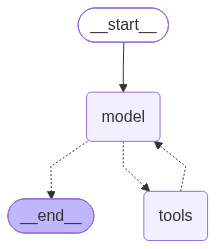

In [7]:
from IPython.display import Image, display

display(Image(agent.get_graph().draw_mermaid_png()))

### 举例2：调用langchain内置的工具

In [8]:
from langchain_tavily import TavilySearch
from langchain_core.tools import tool
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
from dotenv import load_dotenv
import os
load_dotenv(override=True)
from rich import print as rprint

# 以init_chat_model为例
# model = init_chat_model(
#     model="gpt-5.4-mini",
#     model_provider="openai",
#     api_key=os.getenv("CLOSEAI_API_KEY"),
#     base_url=os.getenv("CLOSEAI_BASE_URL")
# )

model = init_chat_model(
    model="deepseek-v4-flash",
    model_provider="deepseek",
    api_key=os.getenv("DEEPSEEK_API_KEY"),
    base_url=os.getenv("DEEPSEEK_BASE_URL")
)

# 使用内置的工具
web_search = TavilySearch(
    max_results=2,      # 每次搜索最多返回 2 条结果
    tavily_api_key=os.getenv("TAVILY_API_KEY"),
)


agent = create_agent(
    model = model,
    tools = [web_search]
)


response = agent.invoke({
    "messages" : [
        {"role": "user", "content": "请帮我查询2024年诺贝尔物理学奖得主是谁？"}
    ]
})

rprint(response)

{
    'messages': [
        HumanMessage(
            content='请帮我查询2024年诺贝尔物理学奖得主是谁？',
            additional_kwargs={},
            response_metadata={},
            id='7d5cf119-112a-4c61-8969-a72c7f6e4f94'
        ),
        AIMessage(
            content='我来帮您查询2024年诺贝尔物理学奖得主的信息。',
            additional_kwargs={
                'refusal': None,
                'reasoning_content': 'The user is asking about the 2024 Nobel Prize in Physics winner. Let me 
search for this.\n\nI know the 2024 Nobel Prize in Physics was awarded to John J. Hopfield and Geoffrey E. Hinton 
for foundational discoveries enabling machine learning with artificial neural networks. Let me verify with a 
search.'
            },
            response_metadata={
                'token_usage': {
                    'completion_tokens': 226,
                    'prompt_tokens': 1838,
                    'total_tokens': 2064,
                    'completion_tokens_details': {
                        'accepted_prediction_tokens': None,
                        'audio_tokens': None,
                        'reasoning_tokens': 63,
                        'rejected_prediction_tokens': None
                    },
                    'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0},
                    'prompt_cache_hit_tokens': 0,
                    'prompt_cache_miss_tokens': 1838
                },
                'model_provider': 'deepseek',
                'model_name': 'deepseek-flash',
                'system_fingerprint': 'aeb56401ca74e127821c4f9126dcb669',
                'id': 'ca742282-e57f-4a6e-a26f-ba1a53c95fb3',
                'finish_reason': 'tool_calls',
                'logprobs': None
            },
            id='lc_run--01a129b1-08e8-7790-ac04-3fb5a2623a9c-0',
            tool_calls=[
                {
                    'name': 'tavily_search',
                    'args': {'query': '2024年诺贝尔物理学奖得主', 'topic': 'general', 'search_depth': 'advanced'},
                    'id': 'call_00_gV6x3g3XCWDxEviUq7OS4935',
                    'type': 'tool_call'
                },
                {
                    'name': 'tavily_search',
                    'args': {
                        'query': '2024 Nobel Prize in Physics winners announcement',
                        'topic': 'general',
                        'search_depth': 'advanced'
                    },
                    'id': 'call_01_8KBqInWgbIjuemaWjNex9015',
                    'type': 'tool_call'
                }
            ],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 1838,
                'output_tokens': 226,
                'total_tokens': 2064,
                'input_token_details': {'cache_read': 0},
                'output_token_details': {'reasoning': 63}
            }
        ),
        ToolMessage(
            content='{"query": "2024年诺贝尔物理学奖得主", "follow_up_questions": null, "answer": null, "images": 
[], "results": [{"url": "https://news.sciencenet.cn/htmlnews/2024/10/531146.shtm", "title": 
"刚刚，2024年诺贝尔物理学奖揭晓！—新闻—科学网", "content": "| |  |  | 作者：冯丽妃，梅进 来源：科学网微信公众号 
发布时间：2024/10/8 17:52:45  选择字号：小 中  大 | | |  |  |  | |  | | 刚刚，2024年诺贝尔物理学奖揭晓！ | |  |    
北京时间10月8日下午5点45分许，2024年诺贝尔物理学奖揭晓。美国普林斯顿大学科学家约翰·霍普菲尔德（John J. 
Hopfield）和加拿大多伦多大学科学家杰弗里·辛顿（Geoffrey E. 
Hinton）获奖，以表彰他们“基于人工神经网络实现机器学习的基础性发现和发明”。  他们用物理学训练人工神经网络  
今年的两位诺贝尔物理学奖得主使用物理学的工具来开发方法，这些方法是当今强大的机器学习的基础。John J. 
Hopfield创造了一种联想记忆，可以存储和重建图像和其他类型的数据模式。Geoffrey 
Hinton发明了一种方法，可以自动发现数据中的属性，从而执行识别图片中的特定元素等任务。  
当我们谈论人工智能时，我们通常指的是使用人工神经网络的机器学习。这项技术最初是受到大脑结构的启发。在人工神经网络中
，大脑的神经元由具有不同值的节点表示。这些节点通过连接相互影响，这些连接可以被比作突触，可以增强或减弱。例如，通过
在同时具有高值的节点之间建立更强的连接来训练网络。今年的获奖者从20世纪80年代开始就在人工神经网络方面开展了重要的工
作。  John [...] |  |\\n\\n|  |\\n|  |\\n| 刚刚，2024年诺贝尔物理学奖揭晓！ |\\n|  
|\\n\\n北京时间10月8日下午5点45分许，2024年诺贝尔物理学奖揭晓。美国普林斯顿大学科学家约翰·霍普菲尔德（John J. 
Hopfield）和加拿大多伦多大学科学家杰弗里·辛顿（Geoffrey E. 
Hinton）获奖，以表彰他们“基于人工神经网络实现机器学习的基础性发现和发明”。\\n\\n他们用物理学训练人工神经网络\\n\\n
今年的两位诺贝尔物理学奖得主使用物理学的工

结果解读：

整体流程和正常的工具调用是一样的

在这里，第一次AIMessage返回结果中进行了并行工具调用，AIMessage.tool_calls 里一次性带了两个 tool_call，大模型决定进行两次并行搜索，一次中文一次英文，所以会一次返回两条 ToolMessage，大模型拿到两条 ToolMessage 后再决定要不要继续调用工具（可能再次调用这个工具，可能调用其他工具），如果不再需要调用，则根据工具调用结果返回一条 AIMessage。

下面这种一次调用两个不同的工具也叫并行调用。

判断是不是“并行调用”，不看工具是不是同一个，而看这些 tool_call 是不是出现在同一条 AIMessage 里。

**“并行”指的是模型侧，不代表运行时一定真并发。**

- 模型侧：一次生成多个 tool_calls，这是并行工具调用。

- 执行侧：LangChain / LangGraph 的 ToolNode 可能用线程池或 asyncio.gather 并发执行，也可能顺序执行，取决于框架实现和工具类型（同步/异步）。

但无论执行是并发还是顺序，语义上都属于“同一批工具调用”，所以仍叫并行工具调用。

### 举例3：绑定多个工具，并调用

In [9]:
from langchain.agents import create_agent
from langchain.tools import tool
from dotenv import load_dotenv
from rich import print as rprint

load_dotenv(override=True)

@tool(parse_docstring=True)
def get_weather(city: str):
    """
    天气查询工具

    Args:
        city: 城市名称
    """
    return f"{city}今天天气挺好"

@tool(parse_docstring=True)
def get_news():
    """
    新闻查询工具
    """
    return "近期，受全球储蓄芯片短缺等多重因素影响，多地回收商称废旧手机回收市场迎来“火热潮”，回收价格普遍上涨，旧手机成“香饽饽”。"

agent = create_agent(
    model,
    tools=[get_weather, get_news]
)
response = agent.invoke({
    "messages": ["你好，杭州今天的天气如何？今天有哪些新闻？"]
})

rprint(response)

{
    'messages': [
        HumanMessage(
            content='你好，杭州今天的天气如何？今天有哪些新闻？',
            additional_kwargs={},
            response_metadata={},
            id='eb444334-c671-4851-85c8-cb5f95f4a6e7'
        ),
        AIMessage(
            content='我来帮您查询杭州的天气和今天的新闻。',
            additional_kwargs={
                'refusal': None,
                'reasoning_content': "The user asks about Hangzhou weather and today's news. I should call both 
tools."
            },
            response_metadata={
                'token_usage': {
                    'completion_tokens': 80,
                    'prompt_tokens': 334,
                    'total_tokens': 414,
                    'completion_tokens_details': {
                        'accepted_prediction_tokens': None,
                        'audio_tokens': None,
                        'reasoning_tokens': 18,
                        'rejected_prediction_tokens': None
                    },
                    'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0},
                    'prompt_cache_hit_tokens': 0,
                    'prompt_cache_miss_tokens': 334
                },
                'model_provider': 'deepseek',
                'model_name': 'deepseek-flash',
                'system_fingerprint': 'aeb56401ca74e127821c4f9126dcb669',
                'id': 'a700ed42-ea7c-4174-b0c8-ca6ca031bc05',
                'finish_reason': 'tool_calls',
                'logprobs': None
            },
            id='lc_run--01a129ba-7999-76e3-b3db-bc8b14a171a9-0',
            tool_calls=[
                {
                    'name': 'get_weather',
                    'args': {'city': '杭州'},
                    'id': 'call_00_5FmHjwPpHG83VWFQUwAp3945',
                    'type': 'tool_call'
                },
                {'name': 'get_news', 'args': {}, 'id': 'call_01_PUeXnPo3Gzj6bJzVeV7R7610', 'type': 'tool_call'}
            ],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 334,
                'output_tokens': 80,
                'total_tokens': 414,
                'input_token_details': {'cache_read': 0},
                'output_token_details': {'reasoning': 18}
            }
        ),
        ToolMessage(
            content='杭州今天天气挺好',
            name='get_weather',
            id='dd1997a3-5f43-4676-8c31-f85f5eb566c3',
            tool_call_id='call_00_5FmHjwPpHG83VWFQUwAp3945'
        ),
        ToolMessage(
            content='近期，受全球储蓄芯片短缺等多重因素影响，多地回收商称废旧手机回收市场迎来“火热潮”，回收价格普遍
上涨，旧手机成“香饽饽”。',
            name='get_news',
            id='9a15bcc1-470d-4769-b2e7-578bbbbfca49',
            tool_call_id='call_01_PUeXnPo3Gzj6bJzVeV7R7610'
        ),
        AIMessage(
            content='你好！以下是为您查询到的信息：\n\n**🌤️ 
杭州今日天气**\n杭州今天天气挺好，适合外出活动。不过工具返回的信息比较简略，建议您出门前再看看具体的温度和穿衣建议
哦。\n\n**📰 
今日新闻**\n近期，受全球存储芯片短缺等多重因素影响，多地回收商称废旧手机回收市场迎来"火热潮"，回收价格普遍上涨，旧
手机成了"香饽饽"。\n\n如果您还想了解其他城市天气或更多新闻，随时告诉我～',
            additional_kwargs={'refusal': None, 'reasoning_content': ''},
            response_metadata={
                'token_usage': {
                    'completion_tokens': 108,
                    'prompt_tokens': 478,
                    'total_tokens': 586,
                    'completion_tokens_details': {
                        'accepted_prediction_tokens': None,
                        'audio_tokens': None,
                        'reasoning_tokens': 0,
                        'rejected_prediction_tokens': None
                    },
                    'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 256},
                    'prompt_cache_hit_tokens': 256,
                    'prompt_cache_miss_tokens': 222
                },
                'model_provider': 'deepseek',
                'model_name': 'deepseek-flash',
                'system_fingerprint': 'aeb56401ca74e127821c4f9126dcb669',
                'id': 'bc81e95f-2d49-4599-abc5-3dbc0b6a0e49',
                'finish_reason': '

## 4、重试机制

举例

In [10]:
from langchain.agents import create_agent
from langchain.tools import tool
from langchain.messages import SystemMessage, HumanMessage
from dotenv import load_dotenv
from rich import print as rprint

load_dotenv(override=True)

flag = 0

@tool
def get_weather(city: str):
    """
    天气查询工具

    Args:
        city: 城市名称
    """
    global flag
    flag += 1

    if flag < 3:
        # raise Exception("暂时无法访问")
        return "TEMP_UNAVAILABLE: 天气服务暂时不可用，请稍后重试"

    return f"{city}今天天气挺好"


messages = [
    SystemMessage("""
    你是一个天气助手。
    当工具返回以 'TEMP_UNAVAILABLE:' 开头的结果时，
    说明是临时故障，不要立即放弃；
    你应再次调用同一个工具，最多重试 3 次。
    如果 3 次后仍失败，再向用户说明服务暂时不可用。
    """),
    HumanMessage("你好，杭州今天的天气如何？")
]
agent = create_agent(model, tools=[get_weather])
response = agent.invoke({"messages": messages})

rprint(response)

# for msg in response["messages"]:
#     msg.pretty_print()

{
    'messages': [
        SystemMessage(
            content="\n    你是一个天气助手。\n    当工具返回以 'TEMP_UNAVAILABLE:' 开头的结果时，\n    
说明是临时故障，不要立即放弃；\n    你应再次调用同一个工具，最多重试 3 次。\n    如果 3 
次后仍失败，再向用户说明服务暂时不可用。\n    ",
            additional_kwargs={},
            response_metadata={},
            id='9a84b9b4-bd42-454f-81fd-4ef31677d6ed'
        ),
        HumanMessage(
            content='你好，杭州今天的天气如何？',
            additional_kwargs={},
            response_metadata={},
            id='a35f3a04-b551-43c4-ad95-cf295c426768'
        ),
        AIMessage(
            content='我来帮您查询杭州今天的天气。',
            additional_kwargs={
                'refusal': None,
                'reasoning_content': 'The user asks about Hangzhou weather. Let me call the tool.'
            },
            response_metadata={
                'token_usage': {
                    'completion_tokens': 60,
                    'prompt_tokens': 374,
                    'total_tokens': 434,
                    'completion_tokens_details': {
                        'accepted_prediction_tokens': None,
                        'audio_tokens': None,
                        'reasoning_tokens': 14,
                        'rejected_prediction_tokens': None
                    },
                    'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0},
                    'prompt_cache_hit_tokens': 0,
                    'prompt_cache_miss_tokens': 374
                },
                'model_provider': 'deepseek',
                'model_name': 'deepseek-flash',
                'system_fingerprint': 'aeb56401ca74e127821c4f9126dcb669',
                'id': '6b68b81f-c6f7-47de-b268-8e03dafcb98e',
                'finish_reason': 'tool_calls',
                'logprobs': None
            },
            id='lc_run--01a129c8-f539-7183-ad45-cf9c803ff5e7-0',
            tool_calls=[
                {
                    'name': 'get_weather',
                    'args': {'city': '杭州'},
                    'id': 'call_00_oRFNwXQJYucG2IIZsOCS2183',
                    'type': 'tool_call'
                }
            ],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 374,
                'output_tokens': 60,
                'total_tokens': 434,
                'input_token_details': {'cache_read': 0},
                'output_token_details': {'reasoning': 14}
            }
        ),
        ToolMessage(
            content='TEMP_UNAVAILABLE: 天气服务暂时不可用，请稍后重试',
            name='get_weather',
            id='ff3a19dc-5711-45f8-a158-8cc1687d4b0b',
            tool_call_id='call_00_oRFNwXQJYucG2IIZsOCS2183'
        ),
        AIMessage(
            content='查询遇到临时故障，我重试一下。',
            additional_kwargs={
                'refusal': None,
                'reasoning_content': 'The tool returned TEMP_UNAVAILABLE, so I should retry, up to 3 times.'
            },
            response_metadata={
                'token_usage': {
                    'completion_tokens': 70,
                    'prompt_tokens': 464,
                    'total_tokens': 534,
                    'completion_tokens_details': {
                        'accepted_prediction_tokens': None,
                        'audio_tokens': None,
                        'reasoning_tokens': 22,
                        'rejected_prediction_tokens': None
                    },
                    'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 256},
                    'prompt_cache_hit_tokens': 256,
                    'prompt_cache_miss_tokens': 208
                },
                'model_provider': 'deepseek',
                'model_name': 'deepseek-flash',
                'system_fingerprint': 'aeb56401ca74e127821c4f9126dcb669',
                'id': '5a072a9e-5441-49c8-992e-4fe7a1b4939e',
                'finish_reason': 'tool_calls',
                'logprobs': None
            },
            id='lc_run--01a129c8-f976-7fb1-b4ec-accc2dc119d7-0',
  

================================ System Message ================================


    你是一个天气助手。
    当工具返回以 'TEMP_UNAVAILABLE:' 开头的结果时，
    说明是临时故障，不要立即放弃；
    你应再次调用同一个工具，最多重试 3 次。
    如果 3 次后仍失败，再向用户说明服务暂时不可用。
    
================================ Human Message =================================

你好，杭州今天的天气如何？
================================== Ai Message ==================================

我来帮您查询杭州今天的天气。
Tool Calls:
  get_weather (call_00_oRFNwXQJYucG2IIZsOCS2183)
 Call ID: call_00_oRFNwXQJYucG2IIZsOCS2183
  Args:
    city: 杭州
================================= Tool Message =================================
Name: get_weather

TEMP_UNAVAILABLE: 天气服务暂时不可用，请稍后重试
================================== Ai Message ==================================

查询遇到临时故障，我重试一下。
Tool Calls:
  get_weather (call_00_rhHg47tQ8e0KWbHbUMhC1486)
 Call ID: call_00_rhHg47tQ8e0KWbHbUMhC1486
  Args:
    city: 杭州
================================= Tool Message =================================
Name: get_weather

TEMP_UNA